# Détection d'Anomalies

## Démarche
Trois approches :
- Statistiques, colonne par colonne (règle IQR, z-score) + contrôles de cohérence entre colonnes
- Multivariée (Isolation Forest, LOF) : une ligne peut être normale sur chaque variable prise seule, mais inhabituelle par la combinaison de ses valeurs
- Patterns fréquents (Apriori / FP-Growth) : quelles variables apparaissent ensemble plus souvent que le hasard

Une anomalie n'est pas forcément une erreur. Une valeur extrême peut être une vraie particularité du coeur, un artefact de mesure ou une erreur de saisie. Ce notebook sert à trouver des potentielles anomalies, pas à dire que ce sont des anomalies définitivement.

In [118]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from scipy import stats
from scipy.signal import find_peaks
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules


On charge les fichiers. `recording_date` est converti en vraie date pour pouvoir faire des comparaisons de dates plus loin

In [119]:
recordings = pd.read_csv("cleaned/cardiac_recordings_cleaned.csv",parse_dates=["recording_date"])
samples = pd.read_csv("cleaned/cardiac_signal_samples_cleaned.csv")

## Anomalies statistiques
### Fonctions IQR et z-score

On applique les deux fonctions : si elles s'accordent, le signal est solide ; si elles divergent, la distribution est probablement asymétrique ou l'échantillon est petit.

`outlier_report` produit un tableau par colonne avec les bornes IQR et le nombre de valeurs hors bornes pour chaque méthode.

In [120]:
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - k * iqr, q3 + k * iqr
    return (s < low) | (s > high), (low, high)

def zscore_outliers(s, thr=3.0):
    z = (s - s.mean()) / s.std(ddof=0)
    return z.abs() > thr, z

def outlier_report(df, cols, k=1.5, thr=3.0):
    rows = []
    for c in cols:
        m_iqr, (lo, hi) = iqr_outliers(df[c], k)
        m_z, _ = zscore_outliers(df[c], thr)
        rows.append({"colonne": c, "min": df[c].min(), "max": df[c].max(),
                     "borne_basse_IQR": lo, "borne_haute_IQR": hi,
                     "n_IQR": int(m_iqr.sum()), "n_zscore": int(m_z.sum())})
    return pd.DataFrame(rows).set_index("colonne")

### Table `recordings` (colonnes numériques)
On commence par les colonnes numériques de `recordings`. Plusieurs ne prennent que quelques valeurs (fréquence de 100 ou 125 Hz, durée de 12 à 30 s, `channel_count` toujours égal à 2) : elles ont peu de chances de contenir des outliers "statistiques". La colonne la plus informative est `device_quality`.

In [121]:
num_cols = ["sampling_rate_hz", "sampling_interval_ms", "duration_seconds",
            "channel_count", "sample_count", "device_quality"]
outlier_report(recordings, num_cols)

,min,max,borne_basse_IQR,borne_haute_IQR,n_IQR,n_zscore
colonne,,,,,,
sampling_rate_hz,100.0,125.0,62.500,162.500,0,0
sampling_interval_ms,8.0,10.0,5.000,13.000,0,0
duration_seconds,12.0,30.0,1.500,37.500,0,0
channel_count,2.0,2.0,2.000,2.000,0,0
sample_count,1200.0,3750.0,-750.000,5250.000,0,0
device_quality,76.9,98.0,76.225,107.225,0,0


Aucune colonne n'a de valeur hors bornes, ni selon l'IQR ni selon le z-score (`n_IQR` = `n_zscore` = 0 partout).
- `channel_count` est constant : IQR = 0, les deux bornes valent 2 et aucune valeur n'en sort.
- `sample_count`, `duration_seconds`, `sampling_rate_hz` : les bornes IQR sont très larges par rapport aux valeurs observées. La borne basse négative de `sample_count` (−750) montre au passage que l'IQR n'a pas beaucoup de sens sur une variable à quelques valeurs fixes. La variabilité ne vient pas d'erreurs.
- `device_quality` est la plus proche de ses bornes : minimum 76,9 contre une borne basse de 76,225. Elle est examinée juste après.

In [122]:
#  enregistrements où IQR ou z-score |z| > 2.5
m_iqr, bounds = iqr_outliers(recordings["device_quality"])
m_z, z = zscore_outliers(recordings["device_quality"], thr=2.5)
recordings["quality_z"] = z
recordings.loc[m_iqr | m_z, ["recording_id", "device_model", "recording_context",
                      "device_quality", "quality_z", "automated_interpretation",
                      "recording_notes_code"]].sort_values("device_quality")

,recording_id,device_model,recording_context,device_quality,quality_z,automated_interpretation,recording_notes_code
8,CRD-410001,Asterion CV-2,rest,76.9,-2.851769,normal,no_note


Cas limite : CRD-410001

`device_quality` = 76,9, soit un z-score de −2,85. Ce n'est pas un outlier très prononcé : 76,9 est juste au-dessus de la borne basse IQR (76,225) et le z-score reste sous le seuil de 3. L'enregistrement apparaît ici parce qu'on a volontairement abaissé le seuil à 2,5 parce qu'on a que 44 enregistrements. Son interprétation automatique est `normal` et sa note `no_note` : la qualité plus faible de l'appareil ne se reflète donc pas dans les champs descriptifs. À garder en tête pour les méthodes suivantes.

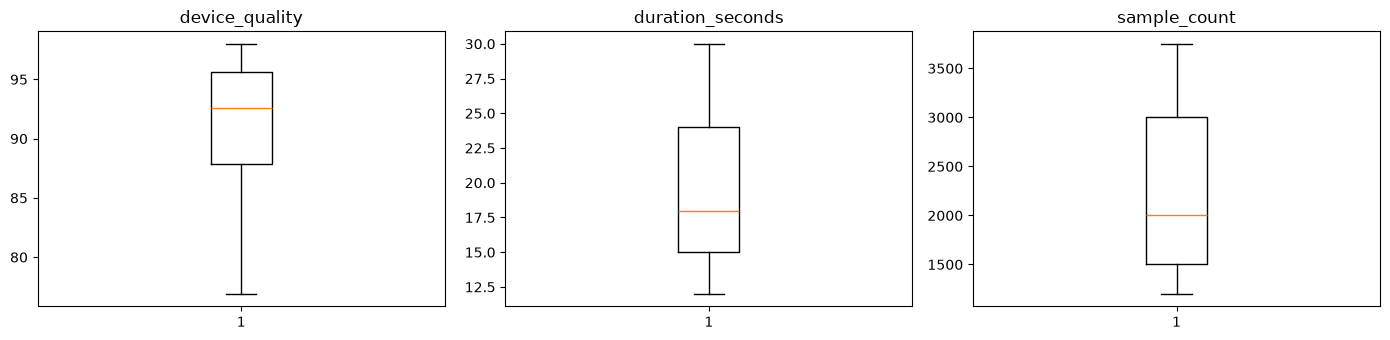

In [123]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ["device_quality", "duration_seconds", "sample_count"]):
    ax.boxplot(recordings[c])
    ax.set_title(c)
plt.tight_layout(); plt.show()

La boîte va de Q1 à Q3, le trait central est la médiane, les moustaches s'étendent jusqu'aux dernières valeurs situées dans les bornes IQR, et tout point isolé au-delà serait un outlier selon la règle IQR. Aucun point isolé ici, ce qui est cohérent avec le tableau. D'après les quartiles, seule `device_quality` est nettement asymétrique : sa moustache basse est plus longue (quelques enregistrements de qualité plus faible).

### 1.3 Table `signal_samples` (niveau signal)

Appliquer IQR / z-score directement sur les 97 000 échantillons détecte surtout les pics R (QRS), qui sont normaux (vu que c'est le signal d'un coeur qui bat) et non des anomalies. On fait donc deux choses :
- compter les points "extrêmes" pour voir l'ampleur,
- résumer chaque enregistrement par des statistiques, puis chercher les enregistrements atypiques.

In [124]:
ch = ["channel_a_normalized", "channel_b_normalized"]
outlier_report(samples, ch, thr=3.0)

,min,max,borne_basse_IQR,borne_haute_IQR,n_IQR,n_zscore
colonne,,,,,,
channel_a_normalized,-1.485359,3.169961,-0.821670,0.877450,6439,2520
channel_b_normalized,-1.587614,2.510826,-0.776033,0.802143,6274,2271


Sur le signal brut, la règle IQR signale environ 6,6% des échantillons du canal A (6439 sur 96925) et le z-score environ 2,6% (2520). C'est beaucoup trop pour de vraies anomalies : on ne détecte pas des erreurs mais la forme normale du signal. Un signal cardiaque reste proche de zéro la plupart du temps, avec un pic bref et élevé à chaque battement. La distribution est donc très asymétrique, avec une longue queue côté positif (max 3,17 contre min −1,49 pour le canal A). Le canal B donne le même résultat. L'IQR, calé sur la partie centrale très resserrée, est plus strict que le z-score. Ces méthodes colonne par colonne ne sont pas adaptées ici, d'où l'approche par enregistrement.

In [125]:
# z-score calculé dans chaque enregistrement (les amplitudes sont pas tjr comparables entre enregistrements)
for c in ch:
    samples[f"{c}_z"] = samples.groupby("recording_id")[c].transform(lambda s: (s - s.mean()) / s.std(ddof=0))

extreme = samples[(samples[[f"{c}_z" for c in ch]].abs() > 4).any(axis=1)]
print(f"{len(extreme)} échantillons avec |z| > 4 dans leur enregistrement "
      f"({len(extreme)/len(samples):.2%}) sur {extreme['recording_id'].nunique()} enregistrements")

# Part d'échantillons extremes par enregistrement
share = (samples[[f"{c}_z" for c in ch]].abs() > 4).any(axis=1).groupby(samples["recording_id"]).mean().sort_values(ascending=False)
share.head(10)

703 échantillons avec |z| > 4 dans leur enregistrement (0.73%) sur 42 enregistrements


recording_id
CRD-410029    0.030000
CRD-410015    0.020500
CRD-410021    0.019667
CRD-410027    0.019667
CRD-410009    0.018667
CRD-410035    0.013333
CRD-410042    0.012667
CRD-410013    0.012000
CRD-410023    0.011111
CRD-410001    0.010000
dtype: float64

Les amplitudes peuvent différer d'un enregistrement à l'autre : on normalise donc à l'intérieur de chacun. Avec un seuil de 4, on trouve 703 échantillons (0,73 %) répartis sur 42 des 44 enregistrements. Les valeurs extrêmes sont donc présentes presque partout en faible proportion, ce qui ressemble aux pics de battements plutôt qu'à un défaut localisé. Le classement met en tête CRD-410029 (3 % d'échantillons extrêmes), suivi de CRD-410015, -410021, -410027 et -410009 autour de 2 %.

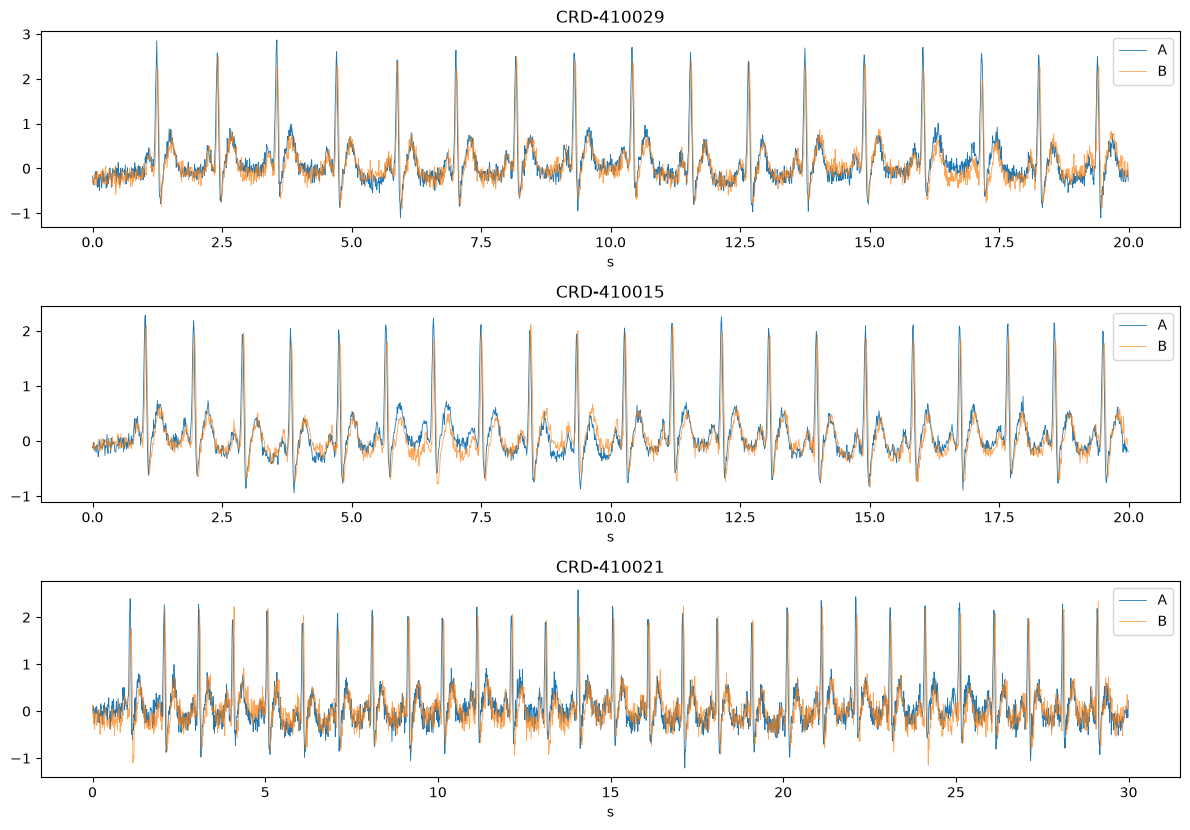

In [126]:
# Visualiser enregistrements les + extrêmes
top = share.head(3).index
fig, axes = plt.subplots(len(top), 1, figsize=(12, 2.8 * len(top)), sharex=False)
for ax, rid in zip(np.atleast_1d(axes), top):
    d = samples[samples.recording_id == rid]
    ax.plot(d.time_ms / 1000, d.channel_a_normalized, lw=.6, label="A")
    ax.plot(d.time_ms / 1000, d.channel_b_normalized, lw=.6, label="B", alpha=.7)
    ax.set_title(rid); ax.set_xlabel("s"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

Chaque graphique montre l'un des enregistrements les plus pointus. À repérer à l'oeil : des pics réguliers à chaque battement (ce qu'on attend, donc valeurs extrêmes) ou au contraire, des pics irréguliers, des sauts brutaux, des zones plates ou une dérive de la ligne de base (signes d'artefact).

### Contrôles de cohérence (équivalent des `cessation_date < appointment_date`)

In [127]:
checks = {}

# sample_count = fréquence * durée
checks["sample_count != rate*duration"] = recordings[recordings.sample_count != recordings.sampling_rate_hz * recordings.duration_seconds]

# intervalle = 1000 / fréquence
checks["interval != 1000/rate"] = recordings[~np.isclose(recordings.sampling_interval_ms, 1000 / recordings.sampling_rate_hz)]

# nombre de lignes de signal = sample_count
n_rows = samples.groupby("recording_id").size()
recordings["n_rows_signal"] = recordings.recording_id.map(n_rows).fillna(0).astype(int)
checks["n_rows_signal != sample_count"] = recordings[recordings.n_rows_signal != recordings.sample_count]

# recordings sans signal / signaux orphelins
checks["recording sans signal"] = recordings[recordings.n_rows_signal == 0]
orphans = set(samples.recording_id) - set(recordings.recording_id)

# pas de temps régulier dans le signal
step = samples.sort_values(["recording_id", "time_ms"]).groupby("recording_id")["time_ms"].diff()
exp_step = samples.recording_id.map(recordings.set_index("recording_id").sampling_interval_ms)
bad_step = samples.loc[step.notna() & (step != exp_step.loc[step.index]), "recording_id"].unique()

# dates et qualité
checks["date dans le futur"] = recordings[recordings.recording_date > pd.Timestamp.today()]
checks["device_quality hors [0,100]"] = recordings[~recordings.device_quality.between(0, 100)]

# doublons patient + date (hors 'technical_repeat' attendu)
dups = recordings[recordings.duplicated(["patient_number", "recording_date"], keep=False)]

for name, d in checks.items():
    print(f"{name:35s} -> {len(d)} ligne(s)")
print("signaux orphelins                   ->", len(orphans))
print("pas de temps irréguliers            ->", len(bad_step), "enregistrement(s)")
print()
dups[["recording_id", "patient_number", "recording_date", "recording_context", "automated_interpretation"]]

sample_count != rate*duration       -> 0 ligne(s)
interval != 1000/rate               -> 0 ligne(s)
n_rows_signal != sample_count       -> 0 ligne(s)
recording sans signal               -> 0 ligne(s)
date dans le futur                  -> 0 ligne(s)
device_quality hors [0,100]         -> 0 ligne(s)
signaux orphelins                   -> 0
pas de temps irréguliers            -> 0 enregistrement(s)



,recording_id,patient_number,recording_date,recording_context,automated_interpretation
0,CRD-410031,PAT-31162,2022-06-21,rest,complex
1,CRD-410019,PAT-31162,2022-06-21,technical_repeat,irregular
5,CRD-410038,PAT-31065,2024-06-12,rest,irregular
6,CRD-410005,PAT-31065,2024-06-12,technical_repeat,review_required


Les 8 contrôles sont tous à 0 : `sample_count` = fréquence * durée, intervalle = 1000 / fréquence, nombre de lignes de signal = `sample_count`, pas de signal seul ni d'enregistrement sans signal, pas de pas de temps irrégulier, pas de date future, `device_quality` bien dans [0, 100]. Les deux fichiers sont donc cohérents entre eux et en interne : si il y a une anomalie, elle est dans le contenu (signal, étiquettes, contexte), pas dans l'intégrité des tables.

Seul résultat non vide : le tableau des doublons `patient_number` + `recording_date`. Il montre 2 paires (PAT-31162 le 2022-06-21, PAT-31065 le 2024-06-12), chacune composée d'un enregistrement `rest` et d'un `technical_repeat`. Ces doublons sont attendus, mais le comportement des répétitions est intéressant :
- Une répétition technique devrait confirmer ou écarter un problème du premier enregistrement. Ici l'interprétation change sans jamais se résoudre en `normal` : `complex` -> `irregular` pour la première paire, `irregular` -> `review_required` pour la seconde.
- Dans les deux paires, la répétition a été faite sur un autre appareil (HelixCard Duo) et sur 30 s (colonnes `device_model` et `duration_seconds`, non affichées ici).

### Statistiques par enregistrement (IQR + z-score entre enregistrements)

In [128]:
def n_peaks(d, col="channel_a_normalized"):
    x = d[col].values
    pk, _ = find_peaks(x, height=x.mean() + 2.5 * x.std(), distance=20)
    return len(pk)

g = samples.groupby("recording_id")
feat = pd.DataFrame({
    "a_mean": g.channel_a_normalized.mean(), "a_std": g.channel_a_normalized.std(),
    "a_min": g.channel_a_normalized.min(),   "a_max": g.channel_a_normalized.max(),
    "a_skew": g.channel_a_normalized.apply(stats.skew),
    "a_kurt": g.channel_a_normalized.apply(stats.kurtosis),
    "b_mean": g.channel_b_normalized.mean(), "b_std": g.channel_b_normalized.std(),
    "b_min": g.channel_b_normalized.min(),   "b_max": g.channel_b_normalized.max(),
    "b_skew": g.channel_b_normalized.apply(stats.skew),
    "b_kurt": g.channel_b_normalized.apply(stats.kurtosis),
    "ab_corr": g.apply(lambda d: d.channel_a_normalized.corr(d.channel_b_normalized)),
    # bruit haute fréquence : écart-type de la différence entre échantillons successifs
    "a_diff_std": g.channel_a_normalized.apply(lambda s: s.diff().std()),
    "b_diff_std": g.channel_b_normalized.apply(lambda s: s.diff().std()),
    "n_peaks_a": g.apply(n_peaks),
})
feat["n_peaks_per_min"] = feat.n_peaks_a / (recordings.set_index("recording_id").duration_seconds / 60)
outlier_report(feat, feat.columns.tolist())

,min,max,borne_basse_IQR,borne_haute_IQR,n_IQR,n_zscore
colonne,,,,,,
a_mean,0.000709,0.173345,0.025506,0.146778,6,0
a_std,0.398662,0.663871,0.324747,0.580419,4,1
a_min,-1.485359,-0.764482,-1.237522,-0.701843,4,0
a_max,1.641902,3.169961,1.329843,2.911602,4,0
a_skew,0.752800,2.272186,1.201003,2.120391,5,1
a_kurt,1.191519,7.134215,2.420759,5.725967,5,0
b_mean,-0.095551,0.109132,-0.009584,0.136802,5,1
b_std,0.364367,0.491534,0.337488,0.487872,1,0
b_min,-1.587614,-0.702803,-1.307762,-0.539586,5,1


- Les deux méthodes ne s'accordent pas complètement : l'IQR signale 4 à 6 enregistrements sur `a_mean`, `a_std`, `a_min`, `a_max`, `a_skew`, `a_kurt`, `b_mean`, `b_min` et `b_max`, alors que le z-score en signale 0 ou 1. Avec 44 lignes, quelques valeurs extrêmes gonflent l'écart-type et masquent les autres, ce qui rend le z-score moins sensible. On est a plusieurs enregistrements en bordure, pas à un outlier évident.
- `n_peaks_a` ne s'interprète pas (durées de 12 à 30 s). `n_peaks_per_min` est la bonne variable. Elle va de 44 à 90 battements/min, plage plausible. Deux valeurs passent sous la borne basse IQR (49,4) : 44 et 45 bpm. La détection de pics est approximative (seuil moyenne + 2,5 d'écart type, distance minimale de 20 échantillons).
- `ab_corr` n'a aucun outlier mais est très dispersée (0,17 à 0,91) : l'accord entre canaux A et B varie beaucoup d'un enregistrement à l'autre. Cette dispersion suit le contexte (calculé hors notebook) : moyenne de 0,34 pour `technical_repeat` contre 0,83 pour `clinical_follow_up`, et les 3 corrélations les plus faibles sont des `technical_repeat`. C'est cohérent avec des répétitions faites pour un problème technique.

In [129]:
# Quels enregistrements sortent le plus souvent ?
flags = pd.DataFrame({c: iqr_outliers(feat[c])[0] | zscore_outliers(feat[c], 3)[0] for c in feat.columns})
flag_count = flags.sum(axis=1).sort_values(ascending=False)
(flag_count[flag_count > 0]
   .to_frame("n_colonnes_aberrantes")
   .join(recordings.set_index("recording_id")[["recording_context", "automated_interpretation", "recording_notes_code", "device_quality"]]))

,n_colonnes_aberrantes,recording_context,automated_interpretation,recording_notes_code,device_quality
recording_id,,,,,
CRD-410020,6,stress_assessment,artefact,baseline_variation,98.0
CRD-410010,5,post_exercise,artefact,baseline_variation,93.6
CRD-410017,4,technical_repeat,review_required,repeat_recommended,95.6
CRD-410008,4,stress_assessment,inconclusive,interference_suspected,95.6
CRD-410029,4,clinical_follow_up,normal,baseline_variation,92.2
CRD-410026,4,rest,artefact,baseline_variation,87.4
CRD-410044,3,post_exercise,inconclusive,interference_suspected,88.7
CRD-410036,3,post_exercise,review_required,repeat_recommended,96.0
CRD-410002,3,technical_repeat,inconclusive,interference_suspected,93.6


17 enregistrements ont au moins une colonne aberrante. En tête : CRD-410020 (6 colonnes) et CRD-410010 (5), puis CRD-410017, -410008, -410029 et -410026 (4 chacun).

- Ce compte est une intensité, pas 6 preuves indépendantes : les variables sont fortement corrélées (`a_mean`, `a_min`, `a_max`, `a_std`, etc... décrivent en partie la même chose).
- Le classement retrouve en grande partie ce que l'interprétation automatique avait déjà noté : plusieurs `artefact` (CRD-410020, -410010, -410026, -410041) et les `inconclusive` avec `interference_suspected` (CRD-410008, -410044, -410002, -410028).
- Exception : CRD-410029 est `normal` mais ressort sur 4 colonnes. C'est le premier candidat inattendu.
- Cinq enregistrements `technical_repeat` apparaissent (CRD-410017, -410002, -410028, -410041, -410005), sur 6 au total dans le fichier.
- `device_quality` ne suit pas ces anomalies : CRD-410020, le plus aberrant, a 98,0, soit le maximum du fichier. Le score de qualité de l'appareil ne reflète donc pas ce qu'on observe sur le signal.

## Anomalies multivariées (Isolation Forest & LOF)

On travaille au niveau enregistrement (44 lignes) avec les variables de métadonnées + les features de signal. Les variables sont standardisées (RobustScaler pour limiter l'influence des valeurs extrêmes elles-mêmes).

In [130]:
meta_num = ["sampling_rate_hz", "duration_seconds", "device_quality"]
X_df = recordings.set_index("recording_id")[meta_num].join(feat)
X_df = X_df.drop(columns=["n_peaks_a"]) # redondant avec n_peaks_per_min
X = RobustScaler().fit_transform(X_df)

CONTAM = 0.10

iso = IsolationForest(n_estimators=500, contamination=CONTAM, random_state=2903)
iso_pred = iso.fit_predict(X) # -1 = anomalie
iso_score = -iso.score_samples(X) # plus grand = plus anormal

lof = LocalOutlierFactor(n_neighbors=10, contamination=CONTAM) # n_neighbors petit car n=44
lof_pred = lof.fit_predict(X)
lof_score = -lof.negative_outlier_factor_

res = X_df.copy()
res["iso_flag"] = iso_pred == -1
res["iso_score"] = iso_score
res["lof_flag"] = lof_pred == -1
res["lof_score"] = lof_score
res = res.join(recordings.set_index("recording_id")[["recording_context", "device_model",
                                              "automated_interpretation", "recording_notes_code"]])
res["both"] = res.iso_flag & res.lof_flag

print("IsolationForest :", res.iso_flag.sum(), "| LOF :", res.lof_flag.sum(), "| les deux :", res.both.sum())
res[res.iso_flag | res.lof_flag].sort_values("iso_score", ascending=False)[
    ["iso_score", "lof_score", "iso_flag", "lof_flag", "device_quality",
     "automated_interpretation", "recording_notes_code", "recording_context"]]

IsolationForest : 5 | LOF : 5 | les deux : 3


,iso_score,lof_score,iso_flag,lof_flag,device_quality,automated_interpretation,recording_notes_code,recording_context
recording_id,,,,,,,,
CRD-410029,0.606585,1.683864,True,True,92.2,normal,baseline_variation,clinical_follow_up
CRD-410010,0.593136,1.682157,True,True,93.6,artefact,baseline_variation,post_exercise
CRD-410002,0.576330,1.508836,True,False,93.6,inconclusive,interference_suspected,technical_repeat
CRD-410020,0.572066,1.779381,True,True,98.0,artefact,baseline_variation,stress_assessment
CRD-410026,0.571746,1.485394,True,False,87.4,artefact,baseline_variation,rest
CRD-410008,0.526710,1.608174,False,True,95.6,inconclusive,interference_suspected,stress_assessment
CRD-410041,0.515580,1.587125,False,True,97.1,artefact,baseline_variation,technical_repeat


**Lecture d'Isolation Forest et de LOF**

- Chaque méthode signale 5 enregistrements, dont 3 en commun : CRD-410029, CRD-410010 et CRD-410020. Le nombre "5" vient de `CONTAM = 0.10` (10% de 44 = ~4,4), pas d'un constat. C'est le classement par score qui nous intéresse.
- Isolation Forest isole les points globalement rares et LOF compare la densité locale. CRD-410002 et CRD-410026 ne sont vus que par Isolation Forest. CRD-410008 et CRD-410041 que par LOF. Les trois enregistrements communs sont les candidats les plus solides.
- Les scores d'Isolation Forest diminuent progressivement (0,61, 0,59, 0,58, 0,57, 0,57, puis 0,53 et 0,52) : pas de rupture franche entre "anormal" et "normal".
- CRD-410029 a le meilleur score Isolation Forest et est signalé par les deux méthodes, alors qu'il est étiqueté `normal`.

variance expliquée : [0.37 0.28]


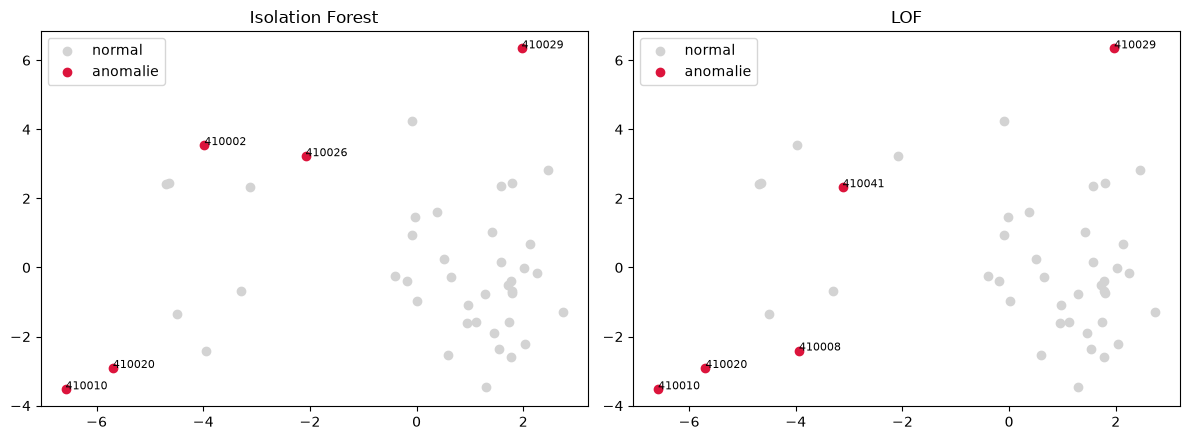

In [131]:
# Projection PCA 2D pour visualiser
p = PCA(n_components=2, random_state=0).fit(X)
Z = p.transform(X)
print("variance expliquée :", p.explained_variance_ratio_.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, flag, title in zip(axes, ["iso_flag", "lof_flag"], ["Isolation Forest", "LOF"]):
    ax.scatter(Z[~res[flag], 0], Z[~res[flag], 1], c="lightgrey", label="normal")
    ax.scatter(Z[res[flag].values, 0], Z[res[flag].values, 1], c="crimson", label="anomalie")
    for i, rid in enumerate(res.index):
        if res.iloc[i][flag]:
            ax.annotate(rid[-6:], (Z[i, 0], Z[i, 1]), fontsize=8)
    ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

Les deux premiers axes expliquent 65% de la variance (0,37 + 0,28) : la projection est assez fidèle sans être complète. Les axes n'ont pas de sens direct sans regarder les contributions des variables.

- CRD-410029 est isolé en haut du graphique (PC2 = ~6), seul dans cette direction.
- CRD-410010 et CRD-410020 sont tout à gauche et en bas (PC1 = ~ −6), dans une autre direction. Il s'agit donc de deux types d'écart : CRD-410029 d'un côté, la paire `artefact` de l'autre.
- Sur la gauche, plusieurs points non signalés (PC1 entre −5 et −3) sont aussi éloignés du nuage principal que certains signalés (CRD-410002, -410026, -410008, -410041). Le seuil de contamination coupe dans une zone de transition : ces quatre enregistrements sont à lire comme des cas limites.

In [132]:
# anomalies détectées recoupent l'interprétation automatique ?
print(pd.crosstab(res.automated_interpretation, res.iso_flag, margins=True))
print()
print(pd.crosstab(res.recording_notes_code, res.iso_flag, margins=True))

iso_flag                  False  True  All
automated_interpretation                  
artefact                      2     3    5
complex                       3     0    3
inconclusive                 12     1   13
irregular                     5     0    5
normal                       11     1   12
review_required               6     0    6
All                          39     5   44

iso_flag                False  True  All
recording_notes_code                    
baseline_variation          5     4    9
interference_suspected      3     1    4
no_note                    14     0   14
repeat_recommended          8     0    8
rhythm_variability          5     0    5
signal_overlap              4     0    4
All                        39     5   44


- Isolation Forest signale 3 des 5 `artefact` (60 % des enregistrements signalés, contre 11 % d'`artefact` dans le fichier) et 4 des 9 `baseline_variation`. Les anomalies multivariées recoupent donc bien les enregistrements déjà jugés mauvais par l'appareil.
- À l'inverse, aucun des 14 enregistrements `complex`, `irregular` ou `review_required` n'est signalé (0/3, 0/5, 0/6). Les variables utilisées décrivent l'amplitude et le bruit du signal, pas la régularité du rythme : aucun problème de rythme ne ressort.
- Les enregistrements `normal` signalés sont ceux qui méritent le plus d'attention : ici 1 sur 12, CRD-410029. L'étiquette automatique et le signal ne sont pas d'accord.

Avec 44 lignes, les résultats dépendent de `contamination`, `n_neighbors` et du jeu de variables. On vérifie la stabilité des enregistrements signalés.

In [133]:
rows = []
for cont in [0.05, 0.10, 0.15]:
    for seed in range(5):
        f = IsolationForest(n_estimators=300, contamination=cont, random_state=seed).fit_predict(X) == -1
        rows.append(pd.Series(f, index=res.index, name=(cont, seed)))
stab = pd.concat(rows, axis=1).mean(axis=1).sort_values(ascending=False)
stab[stab > 0].rename("fréquence de détection (15 runs)").head(15)

recording_id
CRD-410010    1.000000
CRD-410029    1.000000
CRD-410020    0.866667
CRD-410026    0.733333
CRD-410002    0.733333
CRD-410017    0.333333
CRD-410021    0.200000
CRD-410028    0.133333
Name: fréquence de détection (15 runs), dtype: float64

Sur 15 exécutions (3 niveaux de contamination * 5 graines) :
- CRD-410010 et CRD-410029 sont signalés à chaque fois (100 %), y compris à 5 % de contamination où seuls ~2 enregistrements sont retenus : ils restent en tête quel que soit le réglage.
- CRD-410020 est signalé 13 fois sur 15 (87 %), CRD-410026 et CRD-410002 11 fois sur 15 (73 %). Le reste est occasionnel (CRD-410017 33 %, CRD-410021 20 %, CRD-410028 13 %).
- On a donc un noyau stable (CRD-410010, -410029, -410020) et un second cercle (CRD-410026, -410002).

Isolation Forest peut aussi tourner directement sur les ~97000 échantillons (canal A, canal B, dérivées). C'est utile pour localiser des segments anormaux dans un enregistrement.

In [134]:
sig = samples.sort_values(["recording_id", "time_ms"]).reset_index(drop=True)
sig["a_diff"] = sig.groupby("recording_id").channel_a_normalized.diff().fillna(0)
sig["b_diff"] = sig.groupby("recording_id").channel_b_normalized.diff().fillna(0)

Xs = RobustScaler().fit_transform(sig[["channel_a_normalized", "channel_b_normalized", "a_diff", "b_diff"]])
iso_s = IsolationForest(n_estimators=200, contamination=0.01, random_state=2903, n_jobs=-1).fit(Xs)
sig["anom"] = iso_s.predict(Xs) == -1

by_rec = sig.groupby("recording_id").anom.mean().sort_values(ascending=False)
print("Part d'échantillons anormaux par enregistrement (top 8) :")
by_rec.head(8)

Part d'échantillons anormaux par enregistrement (top 8) :


recording_id
CRD-410029    0.044800
CRD-410009    0.040000
CRD-410015    0.037500
CRD-410021    0.036000
CRD-410026    0.031667
CRD-410001    0.028889
CRD-410002    0.026667
CRD-410033    0.022000
Name: anom, dtype: float64

- Avec `contamination=0.01`, 1 % des échantillons sont signalés par construction. La répartition entre enregistrements donne des infos : de 4,5 % (CRD-410029) à 2,2 % (CRD-410033) dans le top 8.
- Les variables (amplitude et dérivée) sont celles qui distinguent les pics R : on retrouve surtout des QRS très hauts ou très raides. Un classement élevé signale un signal plus "pointu", pas forcément une anomalie.
- CRD-410029 est de nouveau premier. Il est premier en z-score extrême, premier en score multivarié et premier ici : c'est la convergence la plus nette du notebook.
- CRD-410009, -410015 et -410021 ressortent ici et dans le z-score par enregistrement, mais pas dans l'analyse multivariée : leurs pics sont hauts, mais leur profil d'ensemble n'est pas atypique.
- CRD-410001 (qualité 76,9, le minimum du fichier) arrive 6e (2,9 %). Le lien est faible, mais c'est le seul entre la métadonnée de qualité et le comportement du signal.

## Patterns fréquents / règles d'association

Variables catégorielles disponibles : `recording_context`, `automated_interpretation`, `recording_notes_code`, `device_model`, `facility_license_number`, `reviewing_license_number`. On ajoute `device_quality` discrétisée.

In [135]:
cat_cols = ["recording_context", "automated_interpretation", "recording_notes_code",
            "device_model", "facility_license_number"]

basket_src = recordings[cat_cols].copy()
basket_src["quality_band"] = pd.cut(recordings.device_quality, [0, 85, 92, 100],
                                    labels=["low", "mid", "high"]).astype(str)

# One-hot "colonne=valeur" (1 item = 1 modalité)
basket = pd.get_dummies(basket_src, prefix_sep="=").astype(bool)
print(basket.shape)
basket.sum().sort_values(ascending=False).head(10)

(44, 27)


facility_license_number=FAC-VLN-101      29
quality_band=high                        25
recording_context=rest                   20
quality_band=mid                         14
recording_notes_code=no_note             14
automated_interpretation=inconclusive    13
automated_interpretation=normal          12
device_model=Vantage Rhythm Monitor      11
device_model=Asterion CV-2               11
device_model=Asterion CV-3               11
dtype: int64

- 44 transactions (une par enregistrement) et 27 items. Les items les plus fréquents sont `facility_license_number=FAC-VLN-101` (29/44, 66%), `quality_band=high` (25), `recording_context=rest` (20), `no_note` (14) et `inconclusive` (13). Les items très fréquents produisent des règles à lift proche de 1, peu informatives.
- `quality_band` est découpée à 85 et 92, des seuils arbitraires qui donnent 5 / 14 / 25 enregistrements (low / mid / high). Le groupe `low` est très petit.
- Le texte d'introduction cite `reviewing_license_number`, mais cette colonne n'est pas dans `cat_cols`. À ajouter (8 modalités, donc supports faibles) ou à retirer du texte, pour rester cohérent.

In [136]:
MIN_SUP = 0.10

fi_apriori = apriori(basket, min_support=MIN_SUP, use_colnames=True)
fi_fp = fpgrowth(basket, min_support=MIN_SUP, use_colnames=True)

# Apriori et FP-Growth doivent donner les mêmes itemsets
same = set(map(frozenset, fi_apriori.itemsets)) == set(map(frozenset, fi_fp.itemsets))
print(f"{len(fi_apriori)} itemsets fréquents | Apriori == FP-Growth : {same}")

fi = fi_fp.assign(length=fi_fp.itemsets.apply(len)).sort_values("support", ascending=False)
fi[fi.length >= 2].head(15)

74 itemsets fréquents | Apriori == FP-Growth : True


,support,itemsets,length
60,0.340909,"frozenset({quality_band=high, facility_license...",2
32,0.250000,"frozenset({quality_band=mid, facility_license_...",2
24,0.250000,"frozenset({recording_context=rest, facility_li...",2
42,0.227273,frozenset({facility_license_number=FAC-VLN-101...,2
26,0.204545,frozenset({device_model=Vantage Rhythm Monitor...,2
51,0.204545,frozenset({automated_interpretation=inconclusi...,2
52,0.181818,"frozenset({quality_band=high, automated_interp...",2
41,0.181818,"frozenset({recording_context=rest, recording_n...",2
33,0.181818,"frozenset({quality_band=mid, recording_context...",2
61,0.181818,frozenset({facility_license_number=FAC-VLN-101...,2


- `MIN_SUP = 0.10` correspond à au moins 5 enregistrements sur 44. 74 itemsets sont retenus. Apriori et FP-Growth donnent exactement les mêmes itemsets : le contrôle passe, et le choix de l'algorithme n'a pas d'impact ici.
- Les itemsets de taille 2 les plus fréquents impliquent `FAC-VLN-101` et `quality_band=high` (34%, soit 15 lignes). Ca reflète les catégories majoritaires, pas une structure en particulier.

In [137]:
rules = association_rules(fi_fp, metric="confidence", min_threshold=0.6)
rules = rules[rules.lift > 1.2].sort_values(["lift", "confidence"], ascending=False)

def fmt(s): return ", ".join(sorted(s))
rules_view = rules.assign(antecedents=rules.antecedents.apply(fmt),
                          consequents=rules.consequents.apply(fmt))
rules_view[["antecedents", "consequents", "support", "confidence", "lift"]].head(20).round(3)

,antecedents,consequents,support,confidence,lift
34,automated_interpretation=artefact,recording_notes_code=baseline_variation,0.114,1.000,4.889
32,recording_context=post_exercise,automated_interpretation=inconclusive,0.114,0.714,2.418
23,"recording_context=rest, recording_notes_code=n...",automated_interpretation=normal,0.114,0.625,2.292
24,"automated_interpretation=normal, recording_con...",recording_notes_code=no_note,0.114,0.714,2.245
2,quality_band=low,recording_context=rest,0.114,1.000,2.200
25,"automated_interpretation=normal, recording_not...",recording_context=rest,0.114,1.000,2.200
9,"facility_license_number=FAC-VLN-101, recording...",quality_band=mid,0.136,0.600,1.886
30,recording_context=clinical_follow_up,quality_band=high,0.114,0.833,1.467
26,recording_notes_code=baseline_variation,quality_band=high,0.159,0.778,1.369
14,facility_license_number=FAC-AVL-201,recording_context=rest,0.136,0.600,1.320


Les règles au lift le plus élevé sont toutes à support 0,114, soit 5 enregistrements :
- `artefact -> baseline_variation` (confiance 1,0, lift 4,9) : les 5 `artefact` portent la note `baseline_variation`, présente sur 9 enregistrements en tout. La règle inverse est moins forte (5/9 = ~0,56). Les deux colonnes sont deux sorties du même traitement automatique : la règle décrit probablement la façon dont les étiquettes sont produites, pas un fait.
- `post_exercise -> inconclusive` (5/7, lift 2,4 ; `inconclusive` représente 30 % du fichier). C'est plausible, le mouvement après effort dégrade le signal. Aucun des 7 enregistrements post-effort n'est `normal`.
- `quality_band=low -> recording_context=rest` (5/5, lift 2,2) : les 5 enregistrements de qualité faible sont tous au repos, ce qui est contre-intuitif (le repos devrait donner le signal le plus propre). Sur 5 lignes seulement.
- Trois règles (lift 2,2 à 2,3) combinent `rest`, `normal` et `no_note` : ce sont trois lectures du même itemset, pas trois résultats distincts.
- Les autres règles ont un lift de 1,26 à 1,9, souvent avec `FAC-VLN-101` ou `quality_band` en conclusion : elles sont proches des fréquences de base.

In [138]:
# Règles dont la conclusion est liée à une interprétation douteuse (artefact / inconclusive / review_required)
mask = rules.consequents.apply(lambda s: any(i.startswith("automated_interpretation=") and
                                              i.split("=")[1] in {"artefact", "inconclusive", "review_required"} for i in s))
rules_view[mask][["antecedents", "consequents", "support", "confidence", "lift"]].round(3)

,antecedents,consequents,support,confidence,lift
32,recording_context=post_exercise,automated_interpretation=inconclusive,0.114,0.714,2.418


Une seule règle conclut à une interprétation douteuse : `post_exercise -> inconclusive`. Aucune règle ne conclut à `artefact` ou à `review_required` avec ces seuils (confiance ≥ 0,6, lift > 1,2, support ≥ 0,10) : le contexte, l'appareil ou l'établissement ne prédisent pas les artefacts. Les 5 `artefact` sont répartis sur 4 contextes différents, donc c'est attendu. La règle `artefact -> baseline_variation` n'apparaît pas ici parce que `artefact` y est en antécédent et non en conclusion.

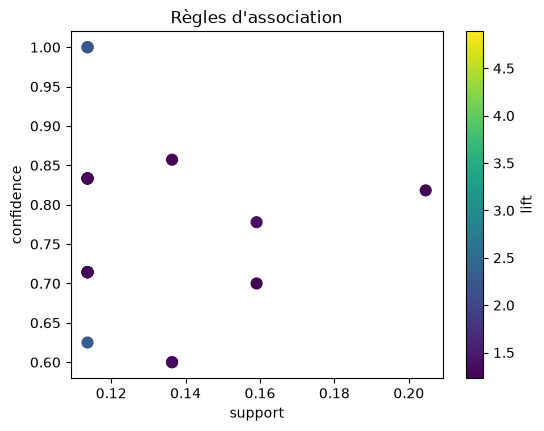

In [139]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sc = ax.scatter(rules.support, rules.confidence, c=rules.lift, s=60, cmap="viridis")
plt.colorbar(sc, label="lift"); ax.set_xlabel("support"); ax.set_ylabel("confidence")
ax.set_title("Règles d'association"); plt.show()

- Toutes les règles ont un support <= 0,20 (9 enregistrements au plus) et la plupart sont au plancher de 0,114 (5 enregistrements) : aucune règle ne concerne une large part du fichier.
- La couleur (lift) est majoritairement sombre (lift < 1,5) : peu de règles sortent du lot.
- Attention à la superposition : le point à (0,114 ; 1,0) apparaît bleu (lift = ~2,2), mais la règle `artefact -> baseline_variation` (lift 4,9) est au même endroit et se trouve masquée. `rules` étant triée par lift décroissant, les lifts faibles sont dessinés en dernier, par-dessus. Trier par lift croissant avant le `scatter`, ou ajouter `alpha`, règle le problème.
- Conclusion : pas de pattern massif dans les variables catégorielles. Les liens qui ressortent sont de petits groupes (5 à 9 lignes), à lire comme des pistes.

## Bilan et pistes

- Les deux fichiers sont intègres : aucune incohérence structurelle parmi les données nettoyées.
- Les méthodes ne voient pas les problèmes de rythme (`complex`, `irregular`), car les variables décrivent l'amplitude et le bruit, pas le rythme
- Peu d'outliers statistiques "purs" : seul `device_quality` de CRD-410001 (76,9) est un cas limite.
- Un noyau d'enregistrements atypiques sur plusieurs méthodes : CRD-410029, CRD-410010, CRD-410020 (puis CRD-410026 et -410002).
  - CRD-410010 et CRD-410020 sont déjà `artefact` : cohérent.
  - CRD-410029 est `normal` (clinical_follow_up, note `baseline_variation`) : le cas le plus intéressant..
